# Exporting models

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
print(np.__version__)
print(pd.__version__)

1.21.6
1.3.5


In [3]:
data = pd.read_csv("../input/regression-with-neural-networking/concrete_data.csv")
data.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


# Data visualization

In [4]:
import matplotlib.pyplot as plt

In [5]:
choose_bins = lambda len: round(1 + 3.322 * np.log(len), 0)

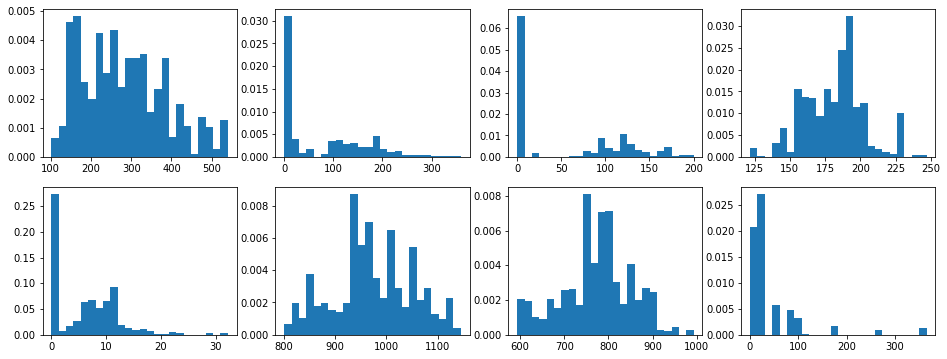

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16,6), )
for ax, col in zip(axes.flatten(), data):
    n_bins = int(choose_bins(len(data[col])))
    plot = data[col].plot(ax=ax ,kind="hist", bins=n_bins, density=True)
    ax.set_ylabel("")

In [7]:
type(data)

pandas.core.frame.DataFrame

In [8]:
type(data["Age"])

pandas.core.series.Series

In [9]:
# Do not use
from pandas.core.frame import DataFrame
from pandas.core.series import Series
def remove_outliers(data: Series):
    q3 = data.quantile(q=0.75)
    q1 = data.quantile(q=0.25)
    iqr =  - data.quantile(q=0.25)
    data = data[(data > q1 - iqr*1.5) & (data < q3 + iqr*1.5)]
    return data

In [10]:
to_predict = ["Strength"]
x_data =  data[filter(to_predict.__ne__, data.columns)].values
y_data = data[to_predict].values

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x_data, y_data, random_state=42, train_size= 0.7)

In [13]:
scaler_x = StandardScaler().fit(x_train)
x_train = scaler_x.transform(x_train)
x_test = scaler_x.transform(x_test)
scaler_y = StandardScaler().fit(y_train)
y_train = scaler_y.transform(y_train)
y_test = scaler_y.transform(y_test)

# Creación del modelo

In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, Dropout
from tensorflow.keras import optimizers
from tensorflow.keras import regularizers
from tensorflow.keras import losses
from tensorflow.keras import metrics

In [15]:
x_train[0].shape

(9,)

In [16]:
model = Sequential()
model.add(Dense(64, input_shape=(9, )))
model.add(Activation('relu'))
model.add(Dense(52))
model.add(Activation('relu'))
model.add(Dense(48))
model.add(Activation('relu'))
model.add(Dense(32))
model.add(Activation('relu'))
model.add(Dense(24))
model.add(Activation('relu'))
# Final layer
model.add(Dense(1))
model.add(Activation('linear'))
          
model.summary()

2022-09-13 04:29:29.199371: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-13 04:29:29.299613: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-13 04:29:29.300535: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero


Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
dense (Dense)                (None, 64)                640       
_________________________________________________________________
activation (Activation)      (None, 64)                0         
_________________________________________________________________
dense_1 (Dense)              (None, 52)                3380      
_________________________________________________________________
activation_1 (Activation)    (None, 52)                0         
_________________________________________________________________
dense_2 (Dense)              (None, 48)                2544      
_________________________________________________________________
activation_2 (Activation)    (None, 48)                0         
_________________________________________________________________
dense_3 (Dense)              (None, 32)                1

2022-09-13 04:29:29.302384: I tensorflow/core/platform/cpu_feature_guard.cc:142] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2022-09-13 04:29:29.302714: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-13 04:29:29.303474: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2022-09-13 04:29:29.304162: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:937] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA 

In [17]:
model.compile(optimizer=optimizers.RMSprop(),
              loss="MeanAbsoluteError",
              metrics=['MeanAbsoluteError']
             )

In [18]:
y_train.mean()

-1.2811450159336064e-16

In [19]:
history = model.fit(x=x_train, y=y_train,
                    batch_size=64,
                    epochs=700,
                    validation_data=(x_test, y_test),
                    verbose=False,
                    validation_steps=1)

2022-09-13 04:29:31.879392: I tensorflow/compiler/mlir/mlir_graph_optimization_pass.cc:185] None of the MLIR Optimization Passes are enabled (registered 2)


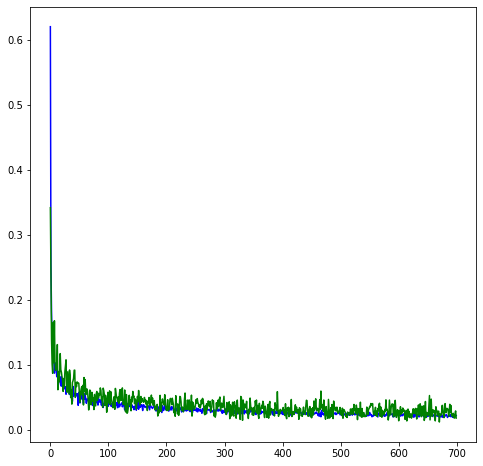

In [20]:
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(history.history['loss'], color="blue")
ax.plot(history.history['val_loss'], color="green")
plt.show()

In [21]:
history.history['val_loss']

[0.34167569875717163,
 0.24298971891403198,
 0.1389012634754181,
 0.10136265307664871,
 0.08698299527168274,
 0.16545961797237396,
 0.103358194231987,
 0.1678769737482071,
 0.1030794233083725,
 0.09149179607629776,
 0.0974062904715538,
 0.0988970547914505,
 0.13122345507144928,
 0.06175483763217926,
 0.08976814150810242,
 0.07355952262878418,
 0.08827558904886246,
 0.11738452315330505,
 0.09261153638362885,
 0.08880243450403214,
 0.08194610476493835,
 0.0754055604338646,
 0.059269942343235016,
 0.07916928827762604,
 0.06617836654186249,
 0.08963146805763245,
 0.09862196445465088,
 0.1077946275472641,
 0.06587061285972595,
 0.05804907903075218,
 0.0894458219408989,
 0.07203423976898193,
 0.05539190024137497,
 0.09217004477977753,
 0.08423501253128052,
 0.0497412383556366,
 0.061349350959062576,
 0.039679523557424545,
 0.07279084622859955,
 0.07557976245880127,
 0.07942358404397964,
 0.09178651869297028,
 0.09196814149618149,
 0.04990958422422409,
 0.07259413599967957,
 0.066598698496818

In [22]:
model.evaluate(x_test, y_test, verbose=False)

[0.020377786830067635, 0.020377786830067635]

In [23]:
sample_number = 20
y_test_sample = y_test[:sample_number]
x_test_sample = x_test[:sample_number]

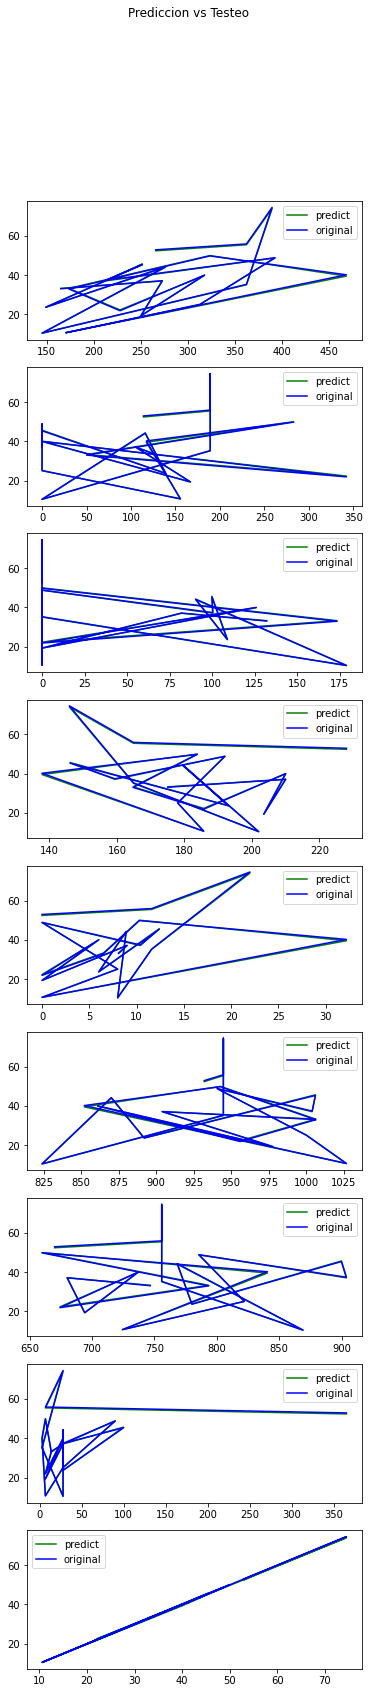

In [24]:
fig, axes = plt.subplots(9,1,figsize=(6,27))
fig.suptitle("Prediccion vs Testeo")
y_pred = scaler_y.inverse_transform(model.predict(x_test_sample))
y_og = scaler_y.inverse_transform(y_test_sample)
for i, ax in zip(range(9), axes.flatten()):
    x_line = scaler_x.inverse_transform(x_test_sample)[:,i]
    ax.plot(x_line, y_pred, color = 'green', label= "predict")
    ax.plot(x_line, y_og, color='blue', label = "original")
    ax.legend()
plt.show()

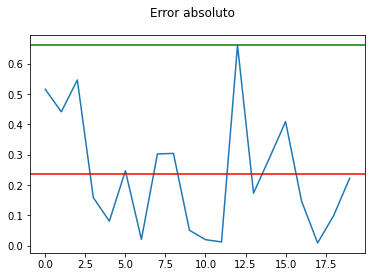

In [25]:
fig, ax = plt.subplots(1,1)
fig.suptitle("Error absoluto")
ax.plot(np.abs(y_pred - y_og))
ax.axhline(np.max(np.abs(y_pred - y_og)), color="green")
ax.axhline(np.mean(np.abs(y_pred - y_og)), color="red")
plt.show()